# 🩸 Proje 2 · Bölüm 3 — Hangi model? Karşılaştırma, kalibrasyon ve klinik fayda
**Seviye: İleri**

Makine öğrenmesinde onlarca model türü var. Bir **makalede** genellikle birkaçı karşılaştırılır. Burada en yaygın 7 modeli, adil bir düzenekle karşılaştıracağız:

| Model | Basit benzetme |
|---|---|
| Lojistik regresyon | Ağırlıklı puan tablosu |
| Karar ağacı | "Evet/hayır" sorularından oluşan algoritma (klinik akış şeması gibi) |
| Rastgele orman | Yüzlerce karar ağacının oylaması ("konsültasyon kurulu") |
| Gradyan artırma (boosting) | Her yeni ağacın öncekilerin hatalarını düzelttiği ekip |
| k-en yakın komşu | "Bu hastaya en çok benzeyen 15 hasta ne olmuştu?" |
| Destek vektör makinesi | İki grubu en geniş "koridor" ile ayıran sınır |
| Yapay sinir ağı (MLP) | Birçok katmanlı esnek fonksiyon |

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 02_Diyabet.zip dosyasını seçin"); files.upload()
    !unzip -q -o 02_Diyabet.zip
    %cd 02_Diyabet
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/02_Diyabet


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json, warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", font_scale=0.9)
OZELLIKLER = ["Gebelik", "Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI", "SoygecmisSkoru", "Yas"]

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

veri = pd.read_csv("veri/diyabet_temiz.csv")
bol = pd.read_json("islenmis/bolunme.json", typ="series")
egt, tst = veri.loc[bol["egitim"]], veri.loc[bol["test"]]
X_egt, y_egt, X_tst, y_tst = egt[OZELLIKLER], egt.Diyabet.values, tst[OZELLIKLER], tst.Diyabet.values

def boru(m, olcekle=True):
    adim = [SimpleImputer(strategy="median")] + ([StandardScaler()] if olcekle else []) + [m]
    return make_pipeline(*adim)

modeller = {
    "Lojistik regresyon": boru(LogisticRegression(max_iter=1000)),
    "Karar ağacı": boru(DecisionTreeClassifier(max_depth=4, min_samples_leaf=15, random_state=0), False),
    "Rastgele orman": boru(RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=0), False),
    "Gradyan artırma": boru(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0), False),
    "k-en yakın komşu": boru(KNeighborsClassifier(n_neighbors=15)),
    "Destek vektör makinesi": boru(SVC(C=1.0, random_state=0)),
    "Yapay sinir ağı (MLP)": boru(MLPClassifier(hidden_layer_sizes=(16, 8), alpha=1e-2, max_iter=3000, random_state=0)),
}

## 1. Tekrarlı çapraz doğrulama: şansa bağlı sonuçlardan kaçınmak
Eğitim setini 5 parçaya bölüp 5 kez eğitiyoruz; bunu 5 farklı karıştırmayla tekrarlıyoruz → **her model için 25 AUC değeri**. Kutunun genişliği, sonucun ne kadar **belirsiz** olduğunu gösterir.

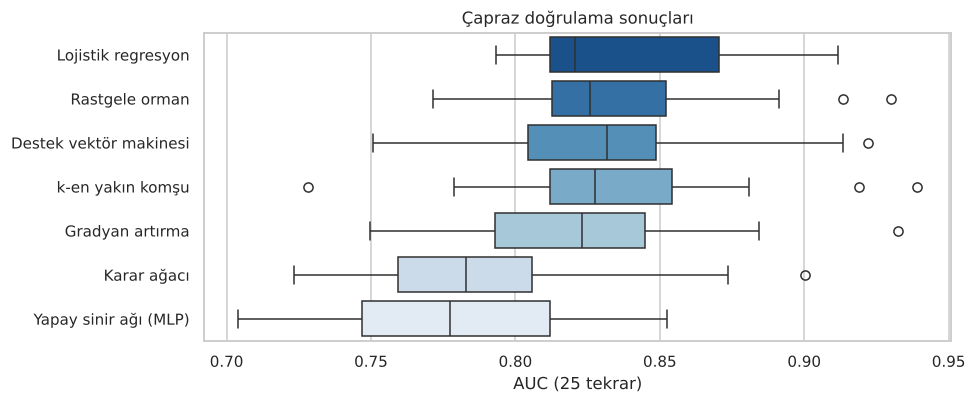

,mean,std
Lojistik regresyon,0.839,0.039
Rastgele orman,0.836,0.038
Destek vektör makinesi,0.833,0.041
k-en yakın komşu,0.833,0.045
Gradyan artırma,0.821,0.042
Karar ağacı,0.791,0.044
Yapay sinir ağı (MLP),0.777,0.041


In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
cv_sonuc = {ad: cross_val_score(m, X_egt, y_egt, cv=cv, scoring="roc_auc") for ad, m in modeller.items()}
cvdf = pd.DataFrame(cv_sonuc)
sira = cvdf.mean().sort_values(ascending=False).index
plt.figure(figsize=(9, 3.8)); sns.boxplot(data=cvdf[sira], orient="h", palette="Blues_r")
plt.xlabel("AUC (25 tekrar)"); plt.title("Çapraz doğrulama sonuçları"); plt.tight_layout(); plt.show()
cvdf.agg(["mean", "std"]).T.loc[sira].round(3)

**Gözlem:** Basit lojistik regresyon, karmaşık modellerle **aynı düzeyde**. Bu, tıbbi tablo verilerinde çok sık görülen bir sonuçtur (bkz. Christodoulou ve ark., *J Clin Epidemiol* 2019: klinik tahmin modellerinde ML'nin lojistik regresyona üstünlüğü sistematik olarak gösterilememiştir). **Daha karmaşık model ≠ daha iyi model.**

## 2. Karar ağacı: en yorumlanabilir model

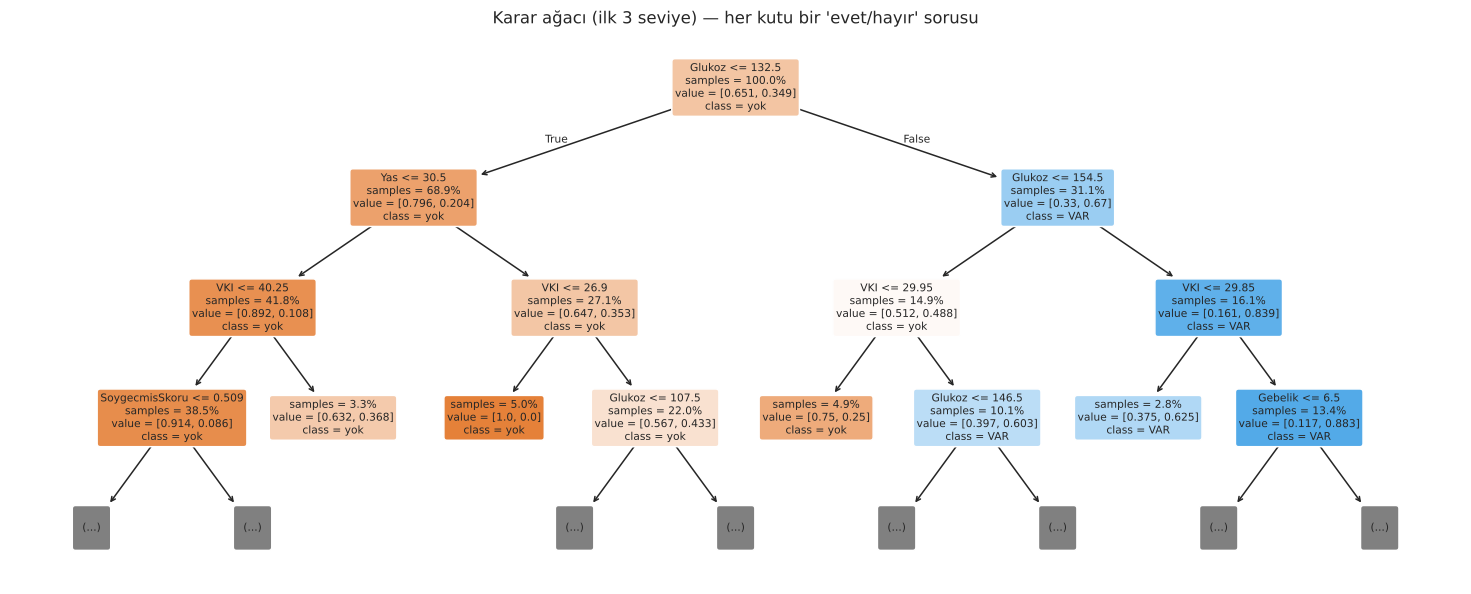

In [4]:
agac = modeller["Karar ağacı"].fit(X_egt, y_egt)
plt.figure(figsize=(17, 6.5))
plot_tree(agac[-1], feature_names=OZELLIKLER, class_names=["yok", "VAR"], filled=True, rounded=True, fontsize=7, impurity=False, proportion=True, max_depth=3)
plt.title("Karar ağacı (ilk 3 seviye) — her kutu bir 'evet/hayır' sorusu"); plt.show()

## 3. Test setinde değerlendirme

In [5]:
olasiliklar = {}
for ad, m in modeller.items():
    m.fit(X_egt, y_egt)
    olasiliklar[ad] = m.predict_proba(X_tst)[:, 1] if hasattr(m, "predict_proba") else None
# SVM olasılık vermez → karar fonksiyonunu lojistik ile kalibre edelim
from sklearn.calibration import CalibratedClassifierCV
svm = boru(CalibratedClassifierCV(SVC(C=1.0, random_state=0), cv=5)).fit(X_egt, y_egt)
olasiliklar["Destek vektör makinesi"] = svm.predict_proba(X_tst)[:, 1]

rng = np.random.default_rng(0)
def auc_ga(y, p, B=1000):          # bootstrap ile %95 güven aralığı
    v = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max(): v.append(roc_auc_score(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

tablo = []
for ad, p in olasiliklar.items():
    lo, hi = auc_ga(y_tst, p)
    tablo.append({"Model": ad, "AUC": roc_auc_score(y_tst, p), "%95 GA": f"{lo:.2f}–{hi:.2f}", "Brier skoru": brier_score_loss(y_tst, p)})
test_tablo = pd.DataFrame(tablo).set_index("Model").sort_values("AUC", ascending=False)
test_tablo.round(3)

,AUC,%95 GA,Brier skoru
Model,,,
Lojistik regresyon,0.824,0.77–0.88,0.170
Gradyan artırma,0.821,0.76–0.88,0.170
Rastgele orman,0.818,0.75–0.88,0.163
k-en yakın komşu,0.800,0.73–0.86,0.172
Destek vektör makinesi,0.797,0.74–0.86,0.177
Karar ağacı,0.781,0.71–0.84,0.177
Yapay sinir ağı (MLP),0.769,0.70–0.84,0.253


**%95 güven aralıkları neredeyse tamamen örtüşüyor** → test setinde 192 kişiyle modeller arasında anlamlı fark gösteremeyiz. Bir makalede "X modeli en iyisi" demeden önce bu belirsizlik mutlaka raporlanmalıdır (TRIPOD+AI kılavuzu).

**Brier skoru**: tahmin edilen olasılıkların gerçeğe ne kadar yakın olduğu (0 = mükemmel).

## 4. Kalibrasyon: "%30 risk" dediğimizde gerçekten 100 kişiden 30'u mu hasta?
Ayırma gücü (AUC) yüksek ama olasılıkları yanlış olan bir model, hastaya risk anlatırken yanıltıcı olur.

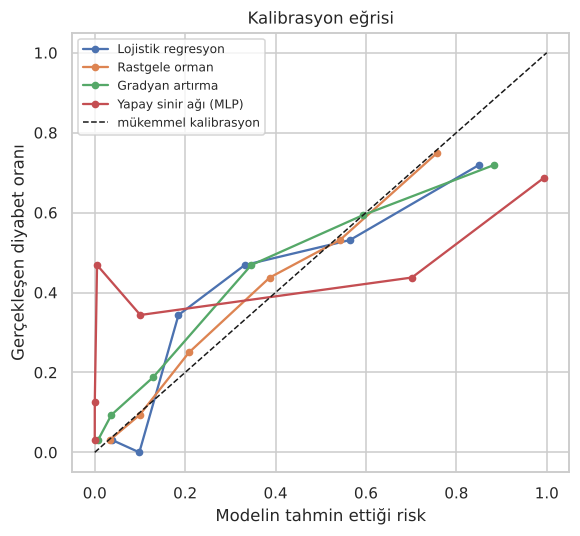

In [6]:
plt.figure(figsize=(5.4, 5))
for ad in ["Lojistik regresyon", "Rastgele orman", "Gradyan artırma", "Yapay sinir ağı (MLP)"]:
    g, t = calibration_curve(y_tst, olasiliklar[ad], n_bins=6, strategy="quantile")
    plt.plot(t, g, "-o", ms=4, label=ad)
plt.plot([0, 1], [0, 1], "k--", lw=1, label="mükemmel kalibrasyon")
plt.xlabel("Modelin tahmin ettiği risk"); plt.ylabel("Gerçekleşen diyabet oranı"); plt.legend(fontsize=8)
plt.title("Kalibrasyon eğrisi"); plt.tight_layout(); plt.show()

## 5. Karar eğrisi analizi (Decision Curve Analysis): model klinikte fayda sağlar mı?
Vickers ve Elkin'in (2006) yöntemi: Her **risk eşiği** için modelin **net faydası**, "herkese test yap" ve "kimseye yapma" stratejileriyle karşılaştırılır.

*Net fayda = (doğru pozitif − yanlış pozitif × eşik/(1−eşik)) / N*

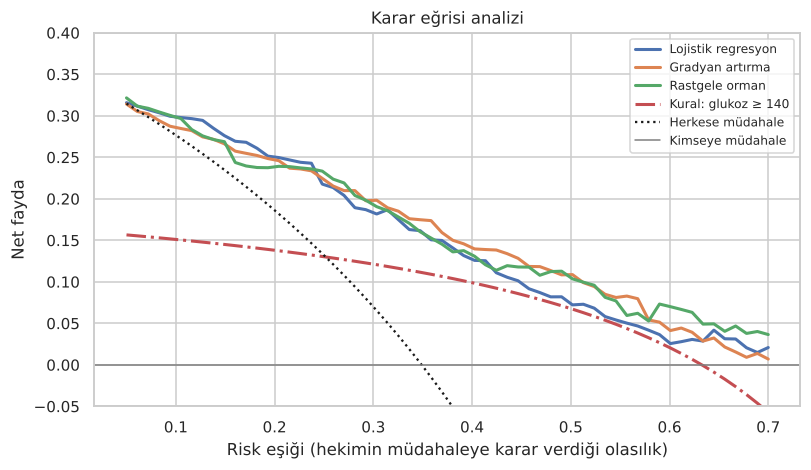

In [7]:
def net_fayda(y, p, esikler):
    N = len(y); nf = []
    for e in esikler:
        t = p >= e; tp = (t & (y == 1)).sum(); fp = (t & (y == 0)).sum()
        nf.append(tp / N - fp / N * e / (1 - e))
    return np.array(nf)

esikler = np.linspace(0.05, 0.7, 60)
plt.figure(figsize=(7.5, 4.4))
for ad in ["Lojistik regresyon", "Gradyan artırma", "Rastgele orman"]:
    plt.plot(esikler, net_fayda(y_tst, olasiliklar[ad], esikler), lw=2, label=ad)
glk = tst["Glukoz"].fillna(117).values
plt.plot(esikler, net_fayda(y_tst, (glk >= 140).astype(float), esikler), lw=2, ls="-.", label="Kural: glukoz ≥ 140")
plt.plot(esikler, net_fayda(y_tst, np.ones_like(y_tst, float), esikler), "k:", label="Herkese müdahale")
plt.axhline(0, c="gray", lw=1, label="Kimseye müdahale")
plt.ylim(-0.05, 0.4); plt.xlabel("Risk eşiği (hekimin müdahaleye karar verdiği olasılık)"); plt.ylabel("Net fayda")
plt.legend(fontsize=8); plt.title("Karar eğrisi analizi"); plt.tight_layout(); plt.show()

In [8]:
test_tablo.to_csv("islenmis/model_karsilastirma.csv")

## ✅ Çıkarımlar
* Bu veri setinde **lojistik regresyon**, karmaşık modellerle aynı başarıdadır, üstelik **yorumlanabilir ve kalibredir** → mobil uygulama için onu seçiyoruz.
* Bir modelin değeri yalnızca AUC ile değil; **kalibrasyon** ve **klinik fayda** (karar eğrisi) ile birlikte değerlendirilmelidir.

💡 **Araştırma fikirleri**
1. Kendi hastanenizin verisiyle (ör. HbA1c, açlık glukozu, bel çevresi) aynı karşılaştırma + **Türk toplumunda dış doğrulama**.
2. FINDRISC gibi klasik risk skorları ile ML modellerinin **karar eğrisi** karşılaştırması.
3. Eksik veri yöntemlerinin (medyan, çoklu imputasyon, eksikliği değişken olarak kullanmak) model başarısına etkisi.